# Market Basket Analysis for Online Retail Product Recommendations

Teresa Ferrill — DSC 680, Project 2, Milestone 2

Question: Can product association rules recover hidden products in later baskets better than a popular-product baseline? This analyzes invoices rather than the customer clusters in the earlier portfolio project.

Run all cells from this project directory. Install requirements first.

## Method and alternatives
FP-growth fits co-purchase data without assuming a purchase sequence. Pair rules limit computational cost and aid interpretation. A popularity baseline tests whether the additional complexity helps. Collaborative filtering is a possible extension; customer clustering addresses a different question.

Chronological development, validation, and test periods prevent future transactions entering rule selection. Candidate products and popularity ranks come only from fitting data. The test basket retains all eligible products, including unseen targets.

## Setup

Install the required packages into the notebook’s active Python environment
before running the analysis:

%pip install -r requirements.txt

Restart the kernel after installation, then run all cells.

In [2]:
import sys
import mlxtend
from mlxtend.frequent_patterns import fpgrowth, association_rules

print("Python version:", sys.version.split()[0])
print("mlxtend version:", mlxtend.__version__)

Python version: 3.13.9
mlxtend version: 0.25.0


In [3]:
from pathlib import Path
import runpy


project = Path.cwd()
script = project / "analysis.py"

assert script.exists(), f"Cannot find analysis.py in {project}"

analysis = runpy.run_path(str(script))

{
  "raw_rows": 541909,
  "clean_rows": 522504,
  "missing_customer_rows_retained": 131354,
  "baskets": 19773,
  "products": 3900,
  "train_baskets": 11044,
  "validation_baskets": 3157,
  "test_baskets": 5572,
  "eligible_test_baskets": 5183,
  "chosen_support": 0.005,
  "chosen_lift": 1.5,
  "rules": 10842,
  "rule_hit_at_5": 0.09839861084314104,
  "baseline_hit_at_5": 0.020065599073895428,
  "coverage": 0.901601389156859,
  "unseen_targets": 340,
  "difference_ci95": [
    0.07003665830600038,
    0.08643642677985723
  ],
  "min_date": "2010-12-01 08:26:00",
  "max_date": "2011-12-09 12:50:00"
}


## Results and interpretation
Hit rate at 5 counts all eligible baskets, including those with no rule recommendation. Coverage is the proportion receiving at least one rule recommendation. The paired bootstrap interval describes uncertainty in the observed basket sample; repeated customers and seasonal dependence limit its interpretation.

In [4]:
import pandas as pd
import json
summary = json.loads((project/'results/summary.json').read_text())
summary

{'raw_rows': 541909,
 'clean_rows': 522504,
 'missing_customer_rows_retained': 131354,
 'baskets': 19773,
 'products': 3900,
 'train_baskets': 11044,
 'validation_baskets': 3157,
 'test_baskets': 5572,
 'eligible_test_baskets': 5183,
 'chosen_support': 0.005,
 'chosen_lift': 1.5,
 'rules': 10842,
 'rule_hit_at_5': 0.09839861084314104,
 'baseline_hit_at_5': 0.020065599073895428,
 'coverage': 0.901601389156859,
 'unseen_targets': 340,
 'difference_ci95': [0.07003665830600038, 0.08643642677985723],
 'min_date': '2010-12-01 08:26:00',
 'max_date': '2011-12-09 12:50:00'}

In [5]:
pd.read_csv(project/'results/cleaning_audit.csv')

,step,removed_rows
0,Missing invoice product or date,0
1,Cancellation invoice,9288
2,Nonpositive or missing quantity or price,2517
3,Nonmerchandise or atypical product code,2379
4,Exact duplicate row,5221


In [6]:
pd.read_csv(project/'results/validation.csv')

,support,lift,rules,hit_rate,coverage,baseline
0,0.005,1.5,10982,0.120924,0.911345,0.030571
1,0.005,1.0,11154,0.120584,0.911345,0.030571
2,0.005,2.0,9970,0.120584,0.909986,0.030571
3,0.010,1.5,1742,0.117188,0.863451,0.030571
4,0.010,1.0,1758,0.116848,0.863451,0.030571
5,0.010,2.0,1616,0.116168,0.863451,0.030571


In [7]:
pd.read_csv(project/'results/rules.csv').head(15)

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,a,b,antecedent_name,consequent_name
0,0.021407,0.021829,0.015844,0.740132,33.905189,1.0,0.015377,3.764099,0.991736,0.578406,0.734332,0.732969,22745,22748,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN
1,0.021829,0.021407,0.015844,0.725806,33.905189,1.0,0.015377,3.568986,0.992164,0.578406,0.719808,0.732969,22748,22745,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM
2,0.022534,0.026618,0.018168,0.806250,30.289831,1.0,0.017568,5.023908,0.989278,0.586364,0.800952,0.744395,84596F,84596B,SMALL MARSHMALLOWS PINK BOWL,SMALL DOLLY MIX DESIGN ORANGE BOWL
3,0.026618,0.022534,0.018168,0.682540,30.289831,1.0,0.017568,3.079019,0.993429,0.586364,0.675221,0.744395,84596B,84596F,SMALL DOLLY MIX DESIGN ORANGE BOWL,SMALL MARSHMALLOWS PINK BOWL
4,0.023097,0.023027,0.015633,0.676829,29.393433,1.0,0.015101,3.023088,0.988817,0.512702,0.669212,0.677864,47590B,47590A,PINK HAPPY BIRTHDAY BUNTING,BLUE HAPPY BIRTHDAY BUNTING
5,0.023027,0.023097,0.015633,0.678899,29.393433,1.0,0.015101,3.042355,0.988746,0.512702,0.671307,0.677864,47590A,47590B,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING
6,0.020914,0.021407,0.012182,0.582492,27.210404,1.0,0.011735,2.343888,0.983825,0.404206,0.573358,0.575785,21671,21670,RED SPOT CERAMIC DRAWER KNOB,BLUE SPOT CERAMIC DRAWER KNOB
7,0.021407,0.020914,0.012182,0.569079,27.210404,1.0,0.011735,2.272077,0.984321,0.404206,0.559874,0.575785,21670,21671,BLUE SPOT CERAMIC DRAWER KNOB,RED SPOT CERAMIC DRAWER KNOB
8,0.022604,0.020210,0.012323,0.545171,26.975534,1.0,0.011866,2.154196,0.985199,0.404157,0.535790,0.577464,23321,23322,SMALL WHITE HEART OF WICKER,LARGE WHITE HEART OF WICKER
9,0.020210,0.022604,0.012323,0.609756,26.975534,1.0,0.011866,2.504577,0.982791,0.404157,0.600731,0.577464,23322,23321,LARGE WHITE HEART OF WICKER,SMALL WHITE HEART OF WICKER


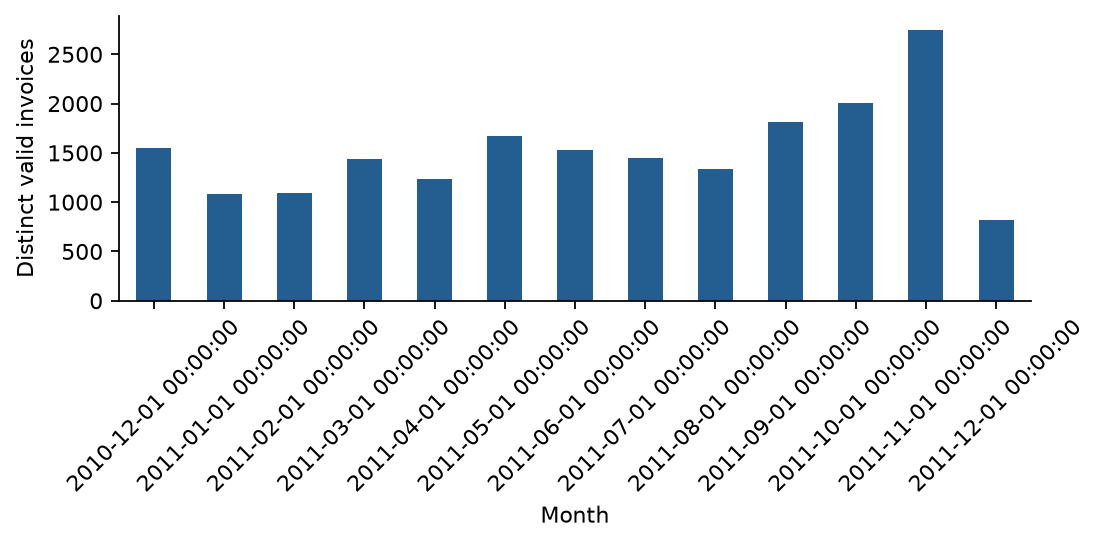

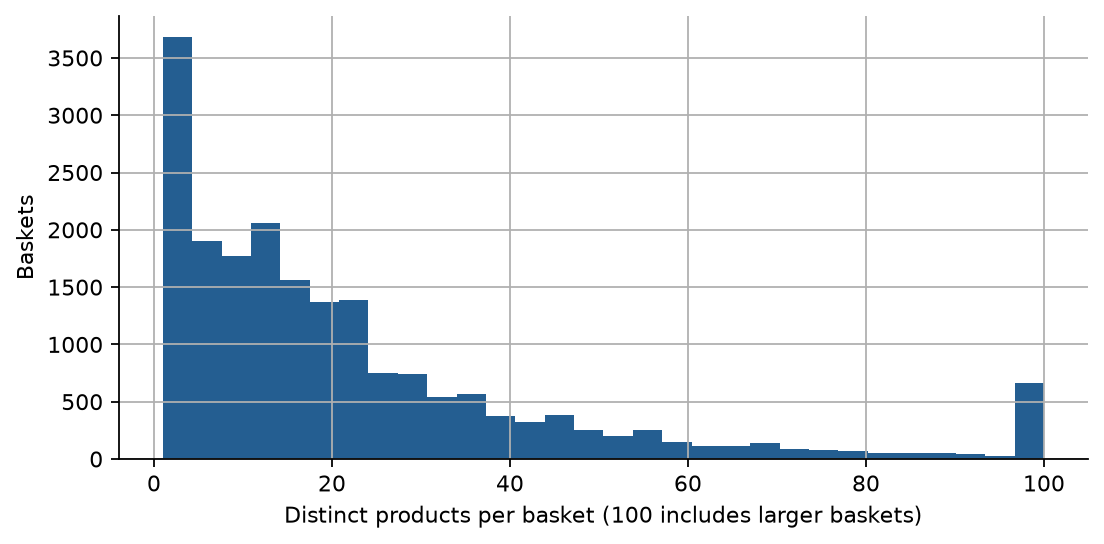

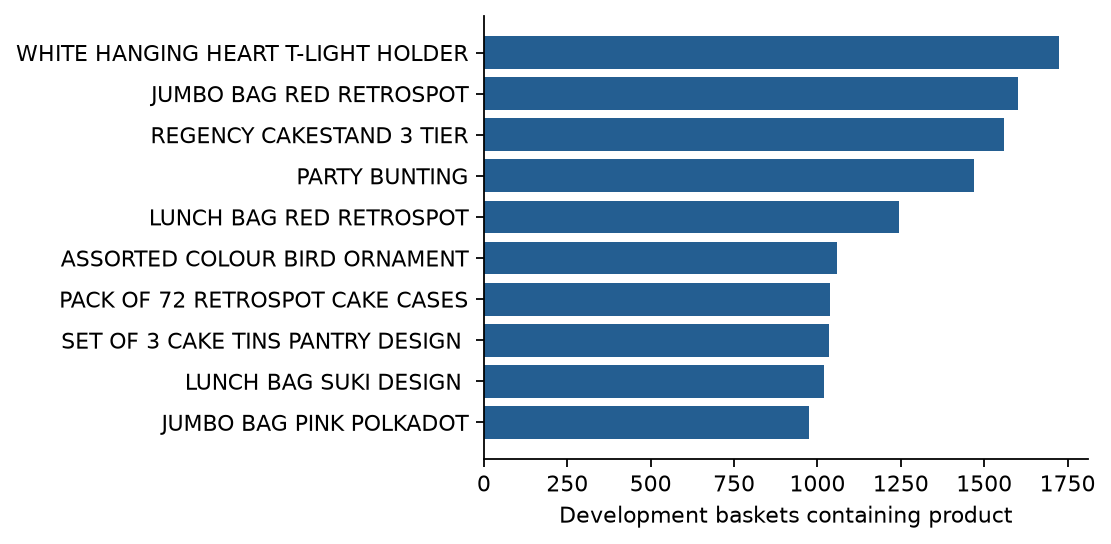

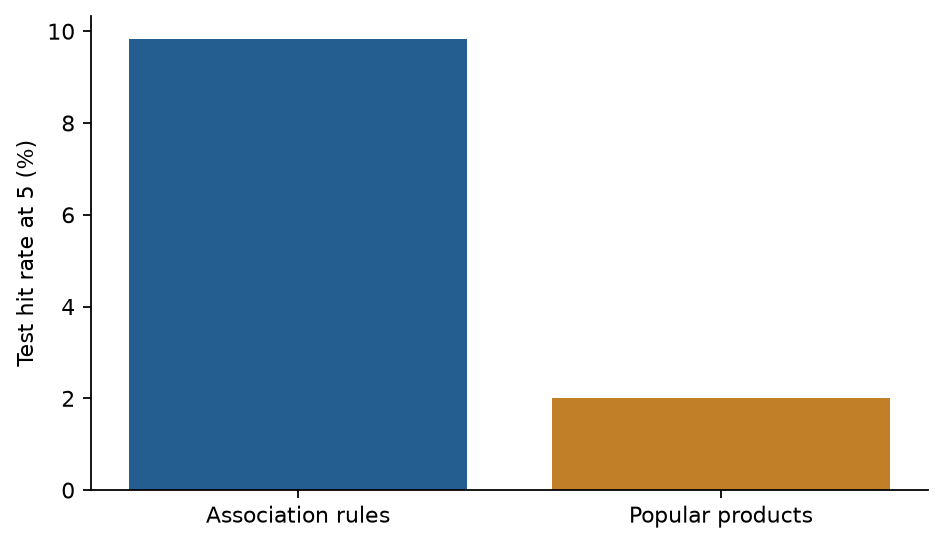

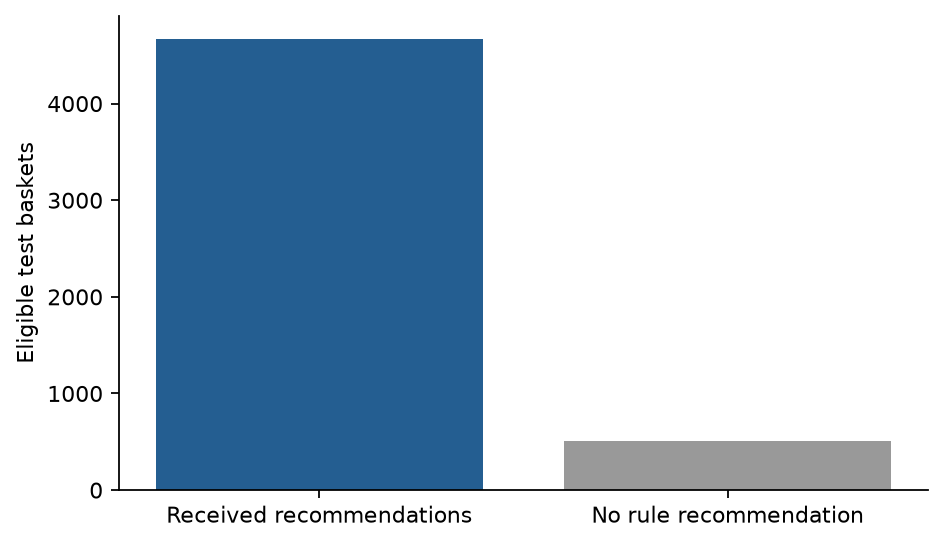

In [8]:
from IPython.display import display, Image
for chart in sorted((project/'results').glob('*.png')):
    display(Image(filename=str(chart)))

## Ethics and limitations
Customer identifiers are unnecessary and are not used for recommendations. Exclusions and missing customer records are documented. Standard merchandise-code filtering may exclude unusual legitimate items. Wholesale baskets, seasonal changes, and popularity affect representativeness. Positive-purchase baskets do not measure net sales. Offline item recovery is not evidence of causal sales gains.

## References
Chen, D. (2015). Online retail [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Han, J., Pei, J., & Yin, Y. (2000). Mining frequent patterns without candidate generation. ACM SIGMOD Record, 29(2), 1–12. https://doi.org/10.1145/335191.335372